In [1]:
# Yayika Tinner - 6722781026
# AI usage: Claude for explanations, debugging help, reword my explanations,
# checking my code & answers, applying small fixes from a rubric review

import sys
import numpy as np
import scipy
import matplotlib.pyplot as plt

# version fingerprint
print("Yayika Tinner - 6722781026")
print("python", sys.version.split()[0], "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| seed: default_rng(2013), refs list as given")

Yayika Tinner - 6722781026
python 3.12.10 | numpy 2.5.3 | scipy 1.18.1 | seed: default_rng(2013), refs list as given


## Part 1 - Compress the fleet and decide what to send

#### 1. Make the fleet

In [2]:
rng = np.random.default_rng(2013)
t = np.arange(8760); day, hour = t // 24, t % 24; hrs = np.arange(24)
rush = np.exp(-(hrs - 8.0)**2/8) + 0.8*np.exp(-(hrs - 19.0)**2/10)
city = (20 + 16*np.cos(2*np.pi*(day - 20)/365)) * (0.55 + 0.45*rush[hour])
weekend = (day % 7 >= 5).astype(float) * rush[hour]
S = 40
gains = rng.uniform(0.7, 1.4, S); traffic = rng.uniform(0.0, 7.0, S)
F = (np.outer(city, gains) + np.outer(rush[hour], traffic)
     - 8.0*np.outer(weekend, np.ones(S))
     + rng.normal(0, 2.0, (8760, S)))             # sensor noise sigma = 2
F[:, 17] = 12.0 + rng.normal(0, 0.3, 8760)        # <- one sensor is quietly faulty
F[:, 31] = F[:, 31] + rng.normal(0, 8.0, 8760)    # <- and another is quietly faulty

m, n = F.shape                            # m = 8760 hours, n = 40 stations
print("fleet table:", F.shape, "=", f"{F.size:,}", "readings in ug/m3")

fleet table: (8760, 40) = 350,400 readings in ug/m3


The fleet is one table: each row is one hour of the year (8,760 rows) and each column is one station (40 columns), so 350,400 readings. The sensor noise is σ = 2 µg/m³, which is the number every error below is compared with.

#### 2. SVD, scree and cumulative energy

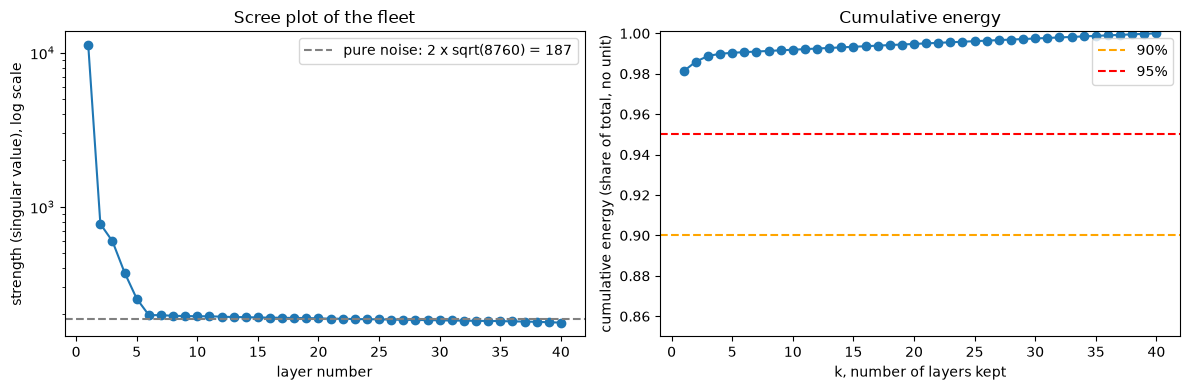

top 6 strengths: [11204.5   774.4   597.4   373.9   253.3   198.2]
strengths 6 to 40 stay between 177.1 and 198.2 (the flat floor)
cumulative energy k = 1..6: [0.9813 0.986  0.9888 0.9899 0.9904 0.9907]
first k with energy >= 0.9: 1
first k with energy >= 0.95: 1
first k with energy >= 0.99: 5


In [3]:
U, s, Vt = np.linalg.svd(F, full_matrices=False)   # layers, strongest first
energy = np.cumsum(s**2) / np.sum(s**2)            # share of the total kept by the first k layers
layer = np.arange(1, n + 1)                        # layer numbers 1..40 for the x axis
noise_level = 2.0 * np.sqrt(m)                     # strength of pure noise (lecture 13 p.45)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].semilogy(layer, s, "o-")
ax[0].axhline(noise_level, color="gray", ls="--", label=f"pure noise: 2 x sqrt(8760) = {noise_level:.0f}")
ax[0].set_xlabel("layer number")
ax[0].set_ylabel("strength (singular value), log scale")
ax[0].set_title("Scree plot of the fleet")
ax[0].legend()

ax[1].plot(layer, energy, "o-")
ax[1].axhline(0.90, color="orange", ls="--", label="90%")
ax[1].axhline(0.95, color="red", ls="--", label="95%")
ax[1].set_ylim(0.85, 1.001)
ax[1].set_xlabel("k, number of layers kept")
ax[1].set_ylabel("cumulative energy (share of total, no unit)")
ax[1].set_title("Cumulative energy")
ax[1].legend()
plt.tight_layout()
plt.show()

print("top 6 strengths:", np.round(s[:6], 1))
print(f"strengths 6 to 40 stay between {s[-1]:.1f} and {s[5]:.1f} (the flat floor)")
print("cumulative energy k = 1..6:", np.round(energy[:6], 4))
for target in (0.90, 0.95, 0.99):
    print(f"first k with energy >= {target}: {np.argmax(energy >= target) + 1}")

The scree plot has a cliff and then a flat floor. Five strengths stand above the floor: 11,204.5, 774.4, 597.4, 373.9 and 253.3. From layer 6 on, the strengths stay level between 198.2 and 177.1. That floor is the sensor noise: pure noise of size 2 spread over 8,760 hours gives a strength of about 2 × √8760 = 187 in every layer (lecture 13, p.45), and the floor sits right around it.

The energy rule does not help here. Layer 1 alone already holds 98.13% of the energy, so the 90% and 95% marks are both passed at k = 1. Layer 1 is the shared city pattern and it is so big that it hides everything else. I report that, and let the elbow choose instead.

In [4]:
# what is each layer? compare its time pattern with the parts of the generator
print("layer | strength | corr with city | corr with rush hour | corr with weekend | biggest station weight")
for i in range(6):
    top = np.argmax(np.abs(Vt[i]))                 # station with the biggest weight in this layer
    c_city = np.corrcoef(U[:, i], city)[0, 1]
    c_rush = np.corrcoef(U[:, i], rush[hour])[0, 1]
    c_wk = np.corrcoef(U[:, i], weekend)[0, 1]
    print(f"  {i+1}   | {s[i]:8.1f} |     {c_city:+.2f}      |       {c_rush:+.2f}        |      {c_wk:+.2f}       |"
          f" station {top} ({Vt[i, top]:+.2f})")

layer | strength | corr with city | corr with rush hour | corr with weekend | biggest station weight
  1   |  11204.5 |     -0.98      |       -0.36        |      +0.04       | station 7 (-0.21)
  2   |    774.4 |     +0.11      |       -0.11        |      -0.03       | station 31 (+0.97)
  3   |    597.4 |     -0.95      |       -0.19        |      +0.11       | station 17 (+0.94)
  4   |    373.9 |     +0.11      |       +0.84        |      +0.23       | station 4 (-0.33)
  5   |    253.3 |     +0.14      |       +0.10        |      +0.65       | station 10 (-0.31)
  6   |    198.2 |     -0.00      |       -0.00        |      +0.00       | station 39 (+0.38)


The sign of a layer can flip on another computer, so I read the size of each number, not its sign (lecture 13, p.28).

- **Layer 1** is the city pattern (correlation size 0.98 with the city signal). Every station carries it.
- **Layer 2** is almost only station 31 (weight 0.97 out of a maximum of 1). It is not a city pattern, it is one station's extra noise.
- **Layer 3** is almost only station 17 (weight 0.94). Its time pattern looks like the city pattern (0.95) because it removes the city pattern that layer 1 put on station 17, which does not follow the city.
- **Layers 4 and 5** are the real smaller patterns: the rush-hour traffic mix between stations (0.84 with the rush-hour shape), and the weekend dip (0.65 with the weekend signal).
- **Layer 6** matches nothing, it is noise like the rest of the floor.

So the five layers above the floor are three real patterns plus two broken sensors. Part 2(c) checks the two broken sensors properly.

**My choice: k = 5.** The elbow is after layer 5: those are all the layers above the noise floor, and layer 6 onwards matches nothing. The energy curve agrees in its own terms: it first reaches 99% at exactly k = 5. I keep layers 2 and 3 for now because the fleet is sending them today. Once stations 17 and 31 are repaired, these two layers disappear and k = 3 would be enough.

#### 3. Storage and error at k

In [5]:
def rmse(a, b):
    return float(np.sqrt(np.mean((a - b)**2)))      # typical gap per reading, in ug/m3

broken = [31, 17]                                   # the stations that own layers 2 and 3 (checked in Part 2)
healthy = [j for j in range(n) if j not in broken]

print(" k | numbers stored | % of 350,400 | RMSE all 40 | RMSE 38 healthy")
for k in range(1, 8):
    A_k = (U[:, :k] * s[:k]) @ Vt[:k]               # copy from the first k layers
    stored = k * (m + n + 1)
    print(f" {k} |     {stored:7,d}    |    {100 * stored / F.size:5.2f}     |    {rmse(F, A_k):.3f}    |"
          f"     {rmse(F[:, healthy], A_k[:, healthy]):.3f}")

 k | numbers stored | % of 350,400 | RMSE all 40 | RMSE 38 healthy
 1 |       8,801    |     2.51     |    2.612    |     2.109
 2 |      17,602    |     5.02     |    2.260    |     2.091
 3 |      26,403    |     7.54     |    2.023    |     2.065
 4 |      35,204    |    10.05     |    1.921    |     1.971
 5 |      44,005    |    12.56     |    1.873    |     1.922
 6 |      52,806    |    15.07     |    1.843    |     1.891
 7 |      61,607    |    17.58     |    1.812    |     1.859


In [6]:
K = 5                                             # my choice from the scree plot
budget = K * (m + n + 1)                          # numbers sent for K layers
F_k = (U[:, :K] * s[:K]) @ Vt[:K]                 # the rebuilt year from K layers

print(f"k = {K}: {budget:,} numbers = {100 * budget / F.size:.2f}% of {F.size:,}")
print(f"RMSE all 40 stations: {rmse(F, F_k):.3f} ug/m3")
print(f"RMSE 38 healthy stations: {rmse(F[:, healthy], F_k[:, healthy]):.3f} ug/m3  (sensor noise sigma = 2)")

k = 5: 44,005 numbers = 12.56% of 350,400
RMSE all 40 stations: 1.873 ug/m3
RMSE 38 healthy stations: 1.922 ug/m3  (sensor noise sigma = 2)


At k = 5 the fleet stores 5 × (8,760 + 40 + 1) = 44,005 numbers, which is 12.56% of the 350,400 raw readings. The rebuilt year differs from the raw table by an RMSE (root-mean-square error, the typical gap per reading) of 1.873 µg/m³.

**Compared with the noise:** the sensors already have σ = 2 µg/m³ of random noise. The fair number to compare is the RMSE on the 38 healthy stations, 1.922 µg/m³, because the overall 1.873 is pulled down by layers 2 and 3 copying the two broken stations almost exactly. 1.922 is about the same size as the noise (4% below it).

**What this lets me claim:** the gap between the copy and the raw data is the same size as the random noise that was already in the readings, so no real pattern was lost. What was dropped is mostly noise. It does not let me claim the copy is "better than the sensors". An error below 2 only means some noise is being copied.

The table also shows why I stop at 5: from k = 5 to 7 the healthy RMSE only falls by about 0.03 per layer, while each layer costs 8,801 more numbers. Past the noise floor, more layers just store more noise. The lecture rule 'stop where the error reaches the noise' (lecture 13, p.47) would stop at k = 4, where the healthy RMSE first drops below 2 (1.971). I still keep layer 5, because it stands above the noise floor in the scree plot and matches the weekend dip (0.65), so it is a real pattern. Dropping it would lose the weekend shape to save only 2.5% of the traffic.

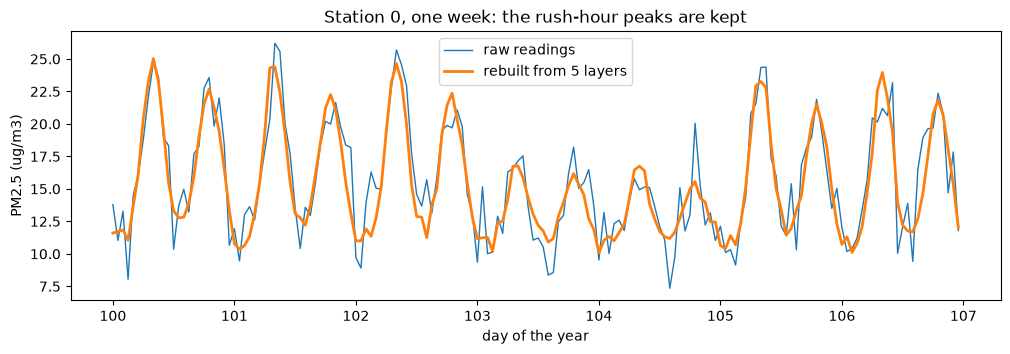

In [7]:
# check the rush-hour peaks survive: one station over one week, raw vs rebuilt
week = slice(100 * 24, 107 * 24)                  # days 100 to 106
plt.figure(figsize=(12, 3.5))
plt.plot(np.arange(7 * 24) / 24 + 100, F[week, 0], label="raw readings", lw=1)
plt.plot(np.arange(7 * 24) / 24 + 100, F_k[week, 0], label=f"rebuilt from {K} layers", lw=2)
plt.xlabel("day of the year")
plt.ylabel("PM2.5 (ug/m3)")
plt.title("Station 0, one week: the rush-hour peaks are kept")
plt.legend()
plt.show()

The rebuilt line follows both daily rush-hour peaks and the quieter weekend. Only the small hour-to-hour jitter (the noise) is missing.

#### 4. Fairness check - the same budget spent on whole rows

In [8]:
rows = budget // n                                # whole hours we can afford with the same budget
R = np.zeros_like(F)
R[:rows] = F[:rows]                               # keep the first hours exactly, blank the rest

print(f"same budget {budget:,} numbers -> {rows:,} whole hours = {rows / 24:.1f} days kept, the rest blanked")
print(f"RMSE keeping rows:  {rmse(F, R):.3f} ug/m3")
print(f"RMSE keeping {K} layers: {rmse(F, F_k):.3f} ug/m3")
print(f"rows are {rmse(F, R) / rmse(F, F_k):.1f} times worse")
print(f"average reading in the blanked hours: {F[rows:].mean():.1f} ug/m3")

same budget 44,005 numbers -> 1,100 whole hours = 45.8 days kept, the rest blanked
RMSE keeping rows:  16.084 ug/m3
RMSE keeping 5 layers: 1.873 ug/m3
rows are 8.6 times worse
average reading in the blanked hours: 14.3 ug/m3


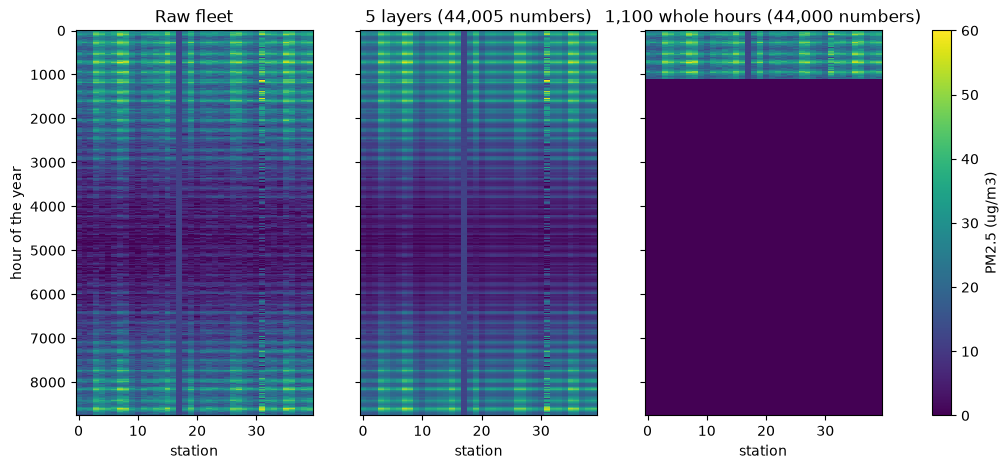

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(13, 5), sharey=True)
panels = [(F, "Raw fleet"), (F_k, f"{K} layers ({budget:,} numbers)"), (R, f"{rows:,} whole hours ({rows * n:,} numbers)")]
for a, (table, title) in zip(ax, panels):
    im = a.imshow(table, aspect="auto", cmap="viridis", vmin=0, vmax=60, interpolation="nearest")
    a.set_title(title)
    a.set_xlabel("station")
ax[0].set_ylabel("hour of the year")
fig.colorbar(im, ax=ax, label="PM2.5 (ug/m3)")
plt.show()

With the same 44,005 numbers, keeping whole rows only buys 1,100 hours, about the first 46 days, and everything after that is blank (zero). Its RMSE is 16.084 µg/m³, about 8.6 times worse than the 5 layers (1.873). The middle picture looks the same as the raw fleet, while the right one is black after the first few weeks.

The reason: a kept row is exact for that hour but says nothing about any other hour, so the blanked part is wrong by the whole reading (14.3 µg/m³ on average). A layer covers the whole year and every station at once, so a few layers are roughly right everywhere.

#### 5. The decision

In [10]:
print(f"At k = {K} the fleet sends {100 * budget / F.size:.1f}% of the raw radio traffic "
      f"({budget:,} of {F.size:,} numbers), an {100 - 100 * budget / F.size:.1f}% saving, "
      f"with an error the size of the sensor noise.")

At k = 5 the fleet sends 12.6% of the raw radio traffic (44,005 of 350,400 numbers), an 87.4% saving, with an error the size of the sensor noise.


Yes, the saving is worth making: the fleet sends about one eighth of today's traffic, and the error is no bigger than the noise the sensors already have.

## Part 2 - Read the patterns, and find the broken sensors

#### 1. One healthy station as days x hours, centred

In [11]:
st = 0                                            # a healthy station (not 17 or 31)
D = F[:, st].reshape(365, 24)                     # rows = days, columns = hours
Dc = D - D.mean(axis=0)                           # centre: take away the average day

# lecture check: the column means should be about 0 after centring
print("largest hour mean before centring:", round(np.abs(D.mean(axis=0)).max(), 2))
print(f"largest hour mean after centring:  {np.abs(Dc.mean(axis=0)).max():.1e}")

U2, s2, Vt2 = np.linalg.svd(Dc, full_matrices=False)
evr = s2**2 / np.sum(s2**2)                       # explained-variance ratio
print("top 5 strengths:", np.round(s2[:5], 1))
print("explained-variance ratio, top 4:", np.round(evr[:4], 4))

# for comparison only: what the first share looks like without centring
s_raw = np.linalg.svd(D, compute_uv=False)
print(f"without centring the first share would be {s_raw[0]**2 / np.sum(s_raw**2):.3f} (strength {s_raw[0]:.1f})")

largest hour mean before centring: 20.13
largest hour mean after centring:  1.4e-14
top 5 strengths: [714.6  86.9  46.4  45.7  43.7]
explained-variance ratio, top 4: [0.9283 0.0137 0.0039 0.0038]
without centring the first share would be 0.983 (strength 1517.1)


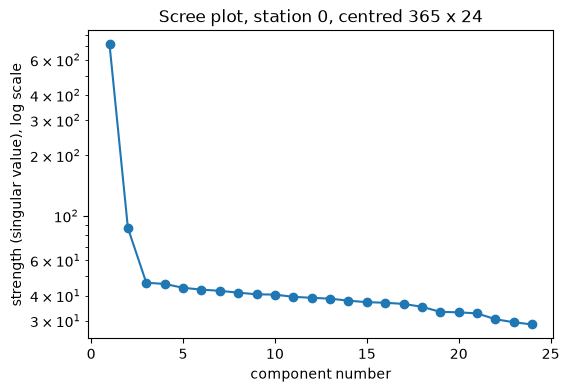

In [12]:
plt.figure(figsize=(6, 4))
plt.semilogy(np.arange(1, 25), s2, "o-")
plt.xlabel("component number")
plt.ylabel("strength (singular value), log scale")
plt.title(f"Scree plot, station {st}, centred 365 x 24")
plt.show()

Centring (subtracting each hour's yearly average) worked: the largest hour mean goes from 20.13 µg/m³ to about 10⁻¹⁴, which is zero.

The scree drops sharply after the first component: 714.6, then 86.9 (8.2 times smaller), then a flat floor from 46.4 on. So two components stand above the noise. The explained-variance ratio is 0.9283 for PC1 (principal component 1) and 0.0137 for PC2: PC1 explains 92.8% of how the days differ from the average day, and PC2 1.4%.

Without centring, the first share would be 0.983. That number is mostly the average day itself, not how the days differ, so it is the wrong number to report (lecture 13, p.70).

#### 2. Name the first two components

In [13]:
days = np.arange(365)
season_level = 20 + 16*np.cos(2*np.pi*(days - 20)/365)      # seasonal level from the generator
weekend_day = (days % 7 >= 5).astype(float)                 # 1 on weekend days, 0 on weekdays

scores = U2[:, :2] * s2[:2]                                 # each day's amount of PC1 and PC2
for i in range(2):
    r_season = np.corrcoef(scores[:, i], season_level)[0, 1]
    r_wk = np.corrcoef(scores[:, i], weekend_day)[0, 1]
    print(f"PC{i+1}: corr with season {r_season:+.3f}, corr with weekend {r_wk:+.3f}")

PC1: corr with season -0.977, corr with weekend +0.212
PC2: corr with season +0.189, corr with weekend +0.876


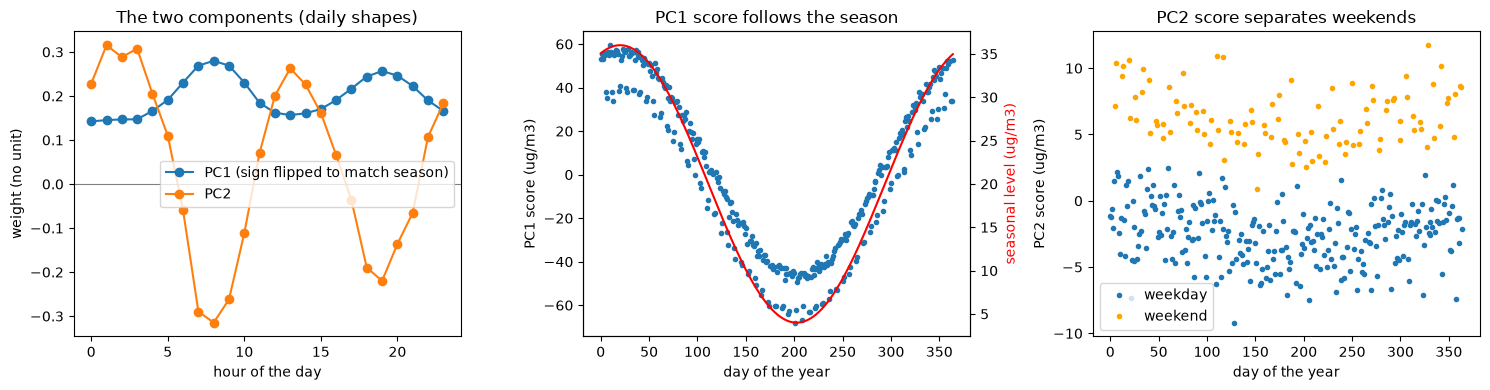

In [14]:
# the sign means nothing, so flip PC1 to point the same way as the season (easier to read)
flip = np.sign(np.corrcoef(scores[:, 0], season_level)[0, 1])

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(hrs, flip * Vt2[0], "o-", label="PC1 (sign flipped to match season)")
ax[0].plot(hrs, Vt2[1], "o-", label="PC2")
ax[0].axhline(0, color="gray", lw=0.8)
ax[0].set_xlabel("hour of the day")
ax[0].set_ylabel("weight (no unit)")
ax[0].set_title("The two components (daily shapes)")
ax[0].legend()

ax[1].plot(days, flip * scores[:, 0], ".", label="PC1 score")
ax[1].set_xlabel("day of the year")
ax[1].set_ylabel("PC1 score (ug/m3)")
ax[1].set_title("PC1 score follows the season")
ax2 = ax[1].twinx()
ax2.plot(days, season_level, color="red", label="seasonal level")
ax2.set_ylabel("seasonal level (ug/m3)", color="red")

wk = weekend_day == 1
ax[2].plot(days[~wk], scores[~wk, 1], ".", label="weekday")
ax[2].plot(days[wk], scores[wk, 1], ".", color="orange", label="weekend")
ax[2].set_xlabel("day of the year")
ax[2].set_ylabel("PC2 score (ug/m3)")
ax[2].set_title("PC2 score separates weekends")
ax[2].legend()
plt.tight_layout()
plt.show()

The signs can flip on another computer, so the size of each correlation is what matters (lecture 13, p.76).

- **PC1 correlates with the seasonal level (−0.977).** The largest way the days differ is that the whole day is dirtier in the cool, dry months: PC1's daily shape has the same sign at every hour, biggest at the 8:00 and 19:00 rush hours.
- **PC2 correlates with the weekend indicator (+0.876).** The second way the days differ is weekend against weekday: in the right plot, the weekend days sit in their own row. PC2's daily shape has opposite signs at night and in the rush hours, so weekend days have less of the rush-hour peak.

The cross correlations are small (PC1 with weekend 0.21, PC2 with season 0.19), so the two names do not overlap. These are correlations, not causes: PCA only shows that the scores move together with the season and the week, not what makes the air dirty.

#### 3. Find the two broken sensors

In [15]:
u1 = U[:, 0]                                      # the fleet's main time pattern (layer 1)
A1 = (U[:, :1] * s[:1]) @ Vt[:1]                  # copy from layer 1 only

means = F.mean(axis=0)
spread = F.std(axis=0)                            # how much each station moves
corr_main = np.array([abs(np.corrcoef(F[:, j], u1)[0, 1]) for j in range(n)])
res1 = np.sqrt(np.mean((F - A1)**2, axis=0))      # what layer 1 cannot explain, per station

print(f"healthy 38: spread {spread[healthy].min():.1f} to {spread[healthy].max():.1f}, "
      f"|corr with main pattern| {corr_main[healthy].min():.3f} to {corr_main[healthy].max():.3f}, "
      f"rank-1 residual median {np.median(res1[healthy]):.2f} (max {res1[healthy].max():.2f})")
for j in (17, 31):
    print(f"station {j}: mean {means[j]:.2f}, spread {spread[j]:.2f}, "
          f"|corr with main pattern| {corr_main[j]:.3f}, rank-1 residual {res1[j]:.2f}")
print("lowest |corr| stations:", np.argsort(corr_main)[:2], " largest residual stations:", np.argsort(-res1)[:2])

swing17 = np.ptp(F[:, 17].reshape(365, 24).mean(axis=0))   # max - min of the average day
swing0 = np.ptp(F[:, 0].reshape(365, 24).mean(axis=0))
print(f"average-day swing: station 17 {swing17:.2f}, station 0 {swing0:.2f} ug/m3")
extra = np.sqrt(res1[31]**2 - np.median(res1[healthy])**2)
print(f"station 31 extra noise ~ sqrt({res1[31]:.2f}^2 - {np.median(res1[healthy]):.2f}^2) = {extra:.2f} ug/m3")

# a trap: at k = 5 these two stations look like the BEST ones
res5 = np.sqrt(np.mean((F - F_k)**2, axis=0))
print(f"residual at k = {K}: station 17 {res5[17]:.2f}, station 31 {res5[31]:.2f}, healthy min {res5[healthy].min():.2f}")

healthy 38: spread 7.4 to 13.0, |corr with main pattern| 0.956 to 0.987, rank-1 residual median 2.06 (max 2.37)
station 17: mean 12.00, spread 0.30, |corr with main pattern| 0.003, rank-1 residual 6.19
station 31: mean 18.63, spread 14.26, |corr with main pattern| 0.824, rank-1 residual 8.10
lowest |corr| stations: [17 31]  largest residual stations: [31 17]
average-day swing: station 17 0.06, station 0 10.40 ug/m3
station 31 extra noise ~ sqrt(8.10^2 - 2.06^2) = 7.83 ug/m3
residual at k = 5: station 17 0.05, station 31 0.03, healthy min 1.80


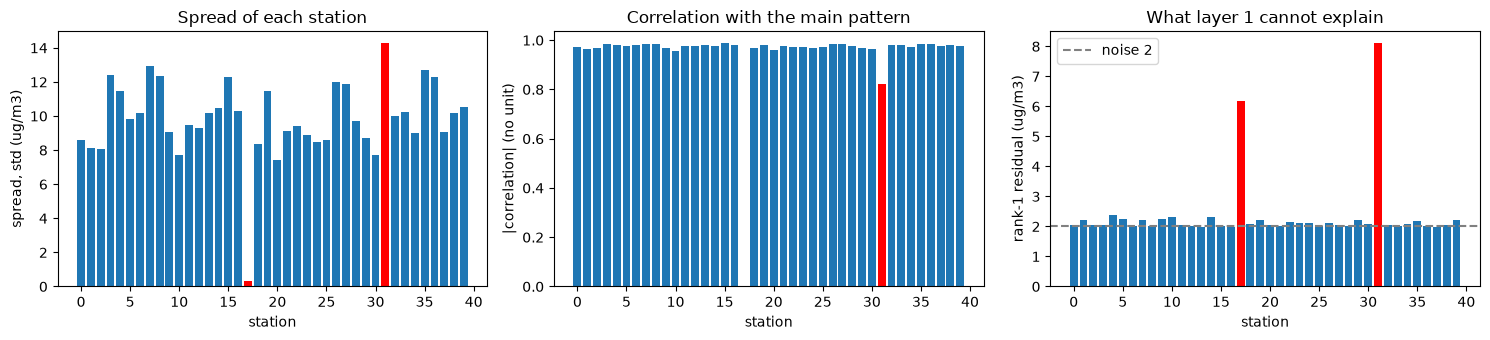

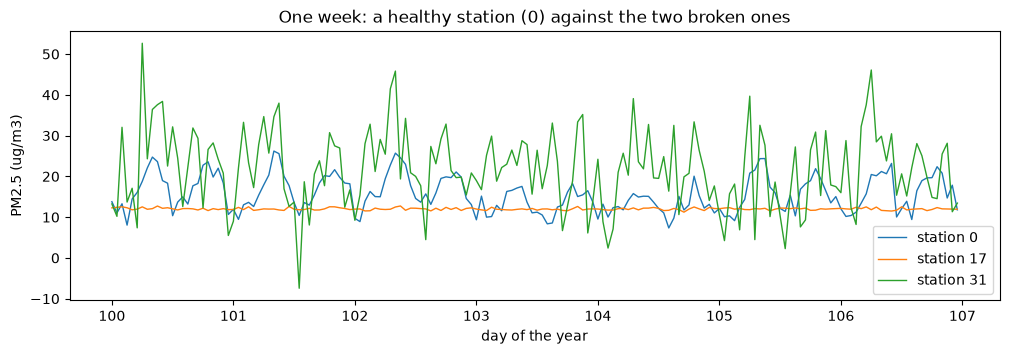

In [16]:
colors = ["red" if j in broken else "tab:blue" for j in range(n)]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ax[0].bar(range(n), spread, color=colors)
ax[0].set_ylabel("spread, std (ug/m3)")
ax[0].set_title("Spread of each station")
ax[1].bar(range(n), corr_main, color=colors)
ax[1].set_ylabel("|correlation| (no unit)")
ax[1].set_title("Correlation with the main pattern")
ax[2].bar(range(n), res1, color=colors)
ax[2].axhline(2.0, color="gray", ls="--", label="noise 2")
ax[2].set_ylabel("rank-1 residual (ug/m3)")
ax[2].set_title("What layer 1 cannot explain")
ax[2].legend()
for a in ax:
    a.set_xlabel("station")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 3.5))
for j in (0, 17, 31):
    plt.plot(np.arange(7 * 24) / 24 + 100, F[week, j], label=f"station {j}", lw=1)
plt.xlabel("day of the year")
plt.ylabel("PM2.5 (ug/m3)")
plt.title("One week: a healthy station (0) against the two broken ones")
plt.legend()
plt.show()

| station | statistic that shows it | diagnosis |
|---|---|---|
| 17 | spread 0.30 µg/m³ (healthy 7.4 to 13.0); correlation 0.003 with the main pattern (healthy at least 0.956); average-day swing 0.06 µg/m³ (station 0: 10.40) | **dead**: it reads about 12.0 all the time, with no rush hour, no weekend and no season. It is not measuring the air. |
| 31 | still follows the city (correlation 0.824, lower than any healthy station); biggest spread in the fleet, 14.26; rank-1 residual 8.10 µg/m³ against a healthy median of 2.06 | **unreliable**: the real signal is there, but with about √(8.10² − 2.06²) = 7.83 µg/m³ of extra noise on top, about four times a healthy sensor's noise |

The week plot shows it directly: station 17 is a flat line, and station 31 follows the same peaks as station 0 but jumps around much more. Part 1 already pointed at both: layer 2 was almost only station 31 and layer 3 almost only station 17.

One trap: at my chosen k = 5 the residuals of stations 17 and 31 are 0.05 and 0.03, the smallest of all 40, because layers 2 and 3 copy them almost exactly. Hunting for broken sensors with the k = 5 residual would call them the best stations. That is why I used the rank-1 residual, the spread and the correlation, which leave those layers out.

#### 4. Would I standardize the columns?

In [17]:
# standardizing divides each column by its own spread
print(f"station 17 would be multiplied by 1/{spread[17]:.2f} = {1 / spread[17]:.1f}")
print(f"healthy stations would be divided by {spread[healthy].min():.1f} to {spread[healthy].max():.1f}")

station 17 would be multiplied by 1/0.30 = 3.3
healthy stations would be divided by 7.4 to 13.0


No. All 40 columns are PM2.5 in the same unit, µg/m³, so their different spreads are real information, not a unit accident. Standardizing would hide station 31's extra spread, and it would multiply dead station 17's flat noise by 3.3 while shrinking every healthy station by 7 to 13 times, so pure noise would look like a real signal. I would only standardize if the columns had different units.

## Part 3 - Rank the reference network with power iteration

#### 1. Build the link matrix and run my own loop

In [18]:
refs = [(0, 3), (3, 0), (3, 5), (7, 3), (7, 0), (12, 3), (12, 5),
        (5, 3), (5, 12), (0, 12), (9, 5), (9, 12), (20, 3), (20, 5)]    # (A, B): A uses B as reference

nodes = sorted({a for a, b in refs} | {b for a, b in refs})             # only stations that appear
idx = {st: i for i, st in enumerate(nodes)}                             # station number -> row/column
N = len(nodes)
out_deg = {st: sum(1 for a, b in refs if a == st) for st in nodes}

M = np.zeros((N, N))
for a, b in refs:
    M[idx[b], idx[a]] += 1.0 / out_deg[a]         # column a shares its trust over its references
print("stations:", nodes, " n =", N)
print("column sums of M:", M.sum(axis=0))

d = 0.85
G = d * M + (1 - d) / N                           # damped link matrix
r = np.ones(N) / N                                # start with equal scores
for it in range(1, 1001):
    r_new = G @ r
    change = np.max(np.abs(r_new - r))            # largest change this round
    r = r_new
    if change < 1e-8:
        break

print(f"converged after {it} iterations (largest change {change:.1e}), scores add to {r.sum():.6f}")
print("check G @ r = r, largest gap:", np.max(np.abs(G @ r - r)))
for i in np.argsort(-r):
    print(f"  station {nodes[i]:2d}: {r[i]:.4f}")
print("top three:", [nodes[i] for i in np.argsort(-r)[:3]])
print(f"floor (1 - d) / n = {(1 - d) / N:.4f}")

stations: [0, 3, 5, 7, 9, 12, 20]  n = 7
column sums of M: [1. 1. 1. 1. 1. 1. 1.]
converged after 23 iterations (largest change 8.5e-09), scores add to 1.000000
check G @ r = r, largest gap: 3.790172398154823e-09
  station  3: 0.3069
  station  5: 0.2589
  station 12: 0.2090
  station  0: 0.1610
  station  7: 0.0214
  station  9: 0.0214
  station 20: 0.0214
top three: [3, 5, 12]
floor (1 - d) / n = 0.0214


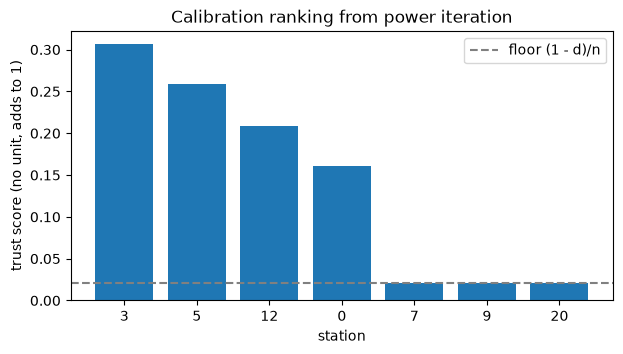

In [19]:
order = np.argsort(-r)
plt.figure(figsize=(7, 3.5))
plt.bar([str(nodes[i]) for i in order], r[order])
plt.axhline((1 - d) / N, color="gray", ls="--", label="floor (1 - d)/n")
plt.xlabel("station")
plt.ylabel("trust score (no unit, adds to 1)")
plt.title("Calibration ranking from power iteration")
plt.legend()
plt.show()

Seven stations appear in the edge list: 0, 3, 5, 7, 9, 12 and 20. Every column of M sums to 1, because each station shares all of its trust equally over the stations it references (every station here references two others, so each edge carries 1/2). My own loop multiplies by G until the largest change is below 10⁻⁸, which takes **23 iterations**. Putting the scores back in gives the same scores (gap about 10⁻⁹), so the loop has settled.

**Top three: station 3 (0.3069), station 5 (0.2589) and station 12 (0.2090).**

#### 2. The most trusted reference

In [20]:
in_deg = {st: sum(1 for a, b in refs if b == st) for st in nodes}
print("references received:", in_deg)
print("stations that use 3:", [a for a, b in refs if b == 3])

references received: {0: 2, 3: 5, 5: 4, 7: 0, 9: 0, 12: 3, 20: 0}
stations that use 3: [0, 7, 12, 5, 20]


**Station 3 is the network's most trusted reference.** It ranks first because five of the seven stations use it as their reference, including the well-trusted stations 5 and 12, so it collects trust from stations that are trusted themselves.

Stations 7, 9 and 20 score exactly 0.0214 = 0.15 / 7, the floor. They reference others, but nobody references them, so they only get the random-jump share. Referencing other stations does not earn trust (lecture 13, p.25).

#### 3. Damping, and a sink

In [21]:
def rank(edges, d):
    # lecture rule (p.21): every round, each station gets (1 - d)/n plus d times the trust flowing in
    Ms = np.zeros((N, N))
    out = {st: sum(1 for a, b in edges if a == st) for st in nodes}
    for a, b in edges:
        Ms[idx[b], idx[a]] += 1.0 / out[a]
    r = np.ones(N) / N
    for it in range(1, 5001):
        r_new = (1 - d) / N + d * (Ms @ r)
        change = np.max(np.abs(r_new - r))
        r = r_new
        if change < 1e-8:
            break
    return r, it

print("same rule on the real network, d = 0.85:", np.round(rank(refs, 0.85)[0], 4))

# make station 3 a sink: others still reference it, but it references nobody
sink_refs = [(a, b) for a, b in refs if a != 3]
for d_try in (1.0, 0.85):
    r_s, it_s = rank(sink_refs, d_try)
    print(f"sink, d = {d_try}: stopped after {it_s} rounds, scores add to {r_s.sum():.4f}, "
          f"station 3 = {r_s[idx[3]]:.4f}, scores {np.round(r_s, 4)}")

same rule on the real network, d = 0.85:

 [0.161  0.3069 0.2589 0.0214 0.0214 0.209  0.0214]
sink, d = 1.0: stopped after 27 rounds, scores add to 0.0000, station 3 = 0.0000, scores [0. 0. 0. 0. 0. 0. 0.]
sink, d = 0.85: stopped after 22 rounds, scores add to 0.3535, station 3 = 0.1141, scores [0.0305 0.1141 0.071  0.0214 0.0214 0.0737 0.0214]


The damping factor d = 0.85 means a person follows a real reference link 85% of the time and jumps to a random station the other 15%, so every station always gets a small share (the 0.0214 floor) and the loop settles on any network. With damping 1.0 and a sink (a station others reference but which references nobody), trust flows into the sink and has nowhere to go, so it leaks out of the network every round: in my test with station 3 made a sink, all scores drained to 0 after 27 rounds and no ranking was left, while with d = 0.85 the random jump adds 0.15/7 to every station each round, so the scores settle (station 3 still first). They only add up to 0.35, not 1, because the sink still leaks the trust that flows into it; the jump stops the total from reaching 0, it does not fix the leak.

The real edge list has no sink, because every station references two others, so this is only a what-if test.